<p style="text-align: center;"> Curso: Machine Learning</p>

<p style="text-align: center;"> Código Curso: 203008067 </p>

<p style="text-align: center;"> Grupo: 203008067_33 </p>

<p style="text-align: center;"> Fase 2 - Componente práctico - Algoritmos supervisados</p>

<p style="text-align: center;">  Presentado por: Luis Angel Quezada Aguirre</p>

<p style="text-align: center;">  Tutor(a): Jorge Luis Quintero</p>

<p style="text-align: center;"> UNIVERSIDAD NACIONAL ABIERTA Y A DISTANCIA - UNAD </p>


# Importación de liberías y datasets

In [1]:
# Manipulación y visualización de datos
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pylab
import scipy.optimize as op

sns.set(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)
pd.set_option('display.float_format', '{:.4f}'.format)

# Machine Learning (sklearn)
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression, Ridge, Lasso, LogisticRegression, Perceptron
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn import preprocessing
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier


print(" Todas las bibliotecas cargadas y configuradas.")


 Todas las bibliotecas cargadas y configuradas.


In [2]:
from sklearn.datasets import fetch_openml
dfr = fetch_openml(data_id=210, as_frame=True, parser="auto")  # data_id ya fija la version en OpenML
dfc = fetch_openml(data_id=1489, as_frame=True, parser="auto")



In [3]:
df1 = dfr.frame
df1.head()


,seeded,season,NC,SC,NWC,TE
0,S,AUTUMN,1.6500,1.8000,3.3300,1.6900
1,U,AUTUMN,1.0900,0.7900,1.5900,0.7400
2,S,WINTER,2.3900,0.3600,2.0600,0.8100
3,U,WINTER,2.9600,1.2700,4.0500,1.4400
4,S,WINTER,4.1600,2.1600,6.0000,2.4800


In [4]:
df2 = dfc.frame
df2.head()


,V1,V2,V3,V4,V5,Class
0,0.4899,-0.4515,-1.0480,-0.5987,-0.0204,1
1,-0.6413,0.1092,0.2921,-0.9168,0.2402,1
2,0.8706,-0.4599,0.5782,0.8066,0.8352,1
3,-0.6284,-0.3163,1.9343,-1.4271,-0.1366,1
4,-0.5964,0.0159,2.0432,-1.6884,-0.9481,1


## Limpieza, preprocesamiento y Análisis exploratorio  de Datos (EDA) del dataset *Phonome (ID:1489)*

El dataset Phoneme fue seleccionado para modelos de clasificación. Contiene información orientada a distinguir entre los sonidos nasales de los orales, por lo que esta (Class) será  la variable objetivo de los modelos; para tal fin, se utilizan datos de las primeras 5 harmónicas AHi/Ene, alojadas en las variables **V1, V2, V3, V4 Y V5** (Gomes Mantovani, 2015). En cuanto a tamaño, el dataset contiene 5404 entradas, distribuidas en 6 columnas/variables, en donde cinco son númerico-decimales y una es binaria.

### Limpieza y preprocesamiento

In [5]:
print("=== CARACTERIZACIÓN DEL DATASET PHONEME (ID:21O) ===")
print(df2.info())

print("\n=== Valores faltantes por columna ===")
print(df2.isnull().sum())

print("\n=== Valores únicos en 'Class' ===")
print(df2['Class'].value_counts(dropna=False))

print("\n=== Valores únicos en 'V1' ===")
print(df2['V1'].value_counts(dropna=False))

print("\n=== Valores únicos en 'V2' ===")
print(df2['V2'].value_counts(dropna=False))


=== CARACTERIZACIÓN DEL DATASET PHONEME (ID:21O) ===
<class 'pandas.DataFrame'>
RangeIndex: 5404 entries, 0 to 5403
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype   
---  ------  --------------  -----   
 0   V1      5404 non-null   float64 
 1   V2      5404 non-null   float64 
 2   V3      5404 non-null   float64 
 3   V4      5404 non-null   float64 
 4   V5      5404 non-null   float64 
 5   Class   5404 non-null   category
dtypes: category(1), float64(5)
memory usage: 216.5 KB
None

=== Valores faltantes por columna ===
V1       0
V2       0
V3       0
V4       0
V5       0
Class    0
dtype: int64

=== Valores únicos en 'Class' ===
Class
1    3818
2    1586
Name: count, dtype: int64

=== Valores únicos en 'V1' ===
V1
-0.5718    2
-0.7434    2
0.2195     2
-0.6621    2
-0.0285    2
          ..
-0.6583    1
-0.0444    1
0.2469     1
-0.7789    1
-0.7946    1
Name: count, Length: 5336, dtype: int64

=== Valores únicos en 'V2' ===
V2
-0.3041    3
-0.2266    3
0.11

In [6]:
df_prep_clf = df2.copy()

# Convertir 'Class' a numérico binario (0/1)
if df_prep_clf['Class'].dtype == 'object' or df_prep_clf['Class'].dtype.name == 'category':
    df_prep_clf['Class'] = pd.Categorical(df_prep_clf['Class']).codes

X_clf = df_prep_clf[['V1', 'V2', 'V3', 'V4', 'V5']]
y_clf = df_prep_clf['Class']

print("✅ Conversión de 'Class' completada.")
print("Distribución de clases:")
print(df_prep_clf['Class'].value_counts())


✅ Conversión de 'Class' completada.
Distribución de clases:
Class
0    3818
1    1586
Name: count, dtype: int64


In [7]:
# DETECCIÓN DE OUTLIERS (IQR)
def detectar_outliers_iqr(df, col):
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    outliers = df[(df[col] < lower) | (df[col] > upper)]
    return len(outliers), lower, upper

print("=== Detección de outliers por variable (método IQR) ===")
for col in X_clf.columns:
    n, lb, ub = detectar_outliers_iqr(X_clf, col)
    pct = 100 * n / len(X_clf)
    print(f"{col}: {n} outliers ({pct:.1f}%) → límites [{lb:.3f}, {ub:.3f}]")


=== Detección de outliers por variable (método IQR) ===
V1: 491 outliers (9.1%) → límites [-2.147, 1.792]
V2: 4 outliers (0.1%) → límites [-3.018, 2.953]
V3: 0 outliers (0.0%) → límites [-3.542, 3.369]
V4: 4 outliers (0.1%) → límites [-2.910, 2.827]
V5: 730 outliers (13.5%) → límites [-1.658, 1.322]


### Análisis Exploratorio de datos (EDA) mediante visualización

In [8]:
print("Estadísticas descriptivas del dataset PHENOME (ID = 210)")
df2.describe()


Estadísticas descriptivas del dataset PHENOME (ID = 210)


,V1,V2,V3,V4,V5
count,5404.0000,5404.0000,5404.0000,5404.0000,5404.0000
mean,0.0000,0.0000,0.0000,-0.0000,-0.0000
std,1.0000,1.0000,1.0000,1.0000,1.0000
min,-2.9337,-3.0387,-2.7959,-2.4853,-2.3675
25%,-0.6698,-0.7791,-0.9506,-0.7583,-0.5405
50%,-0.3802,-0.2151,-0.0386,-0.1423,-0.2127
75%,0.3149,0.7137,0.7771,0.6759,0.2045
max,3.8286,3.6648,2.6309,3.0469,4.5867


**1)** Diagramas de dispersión

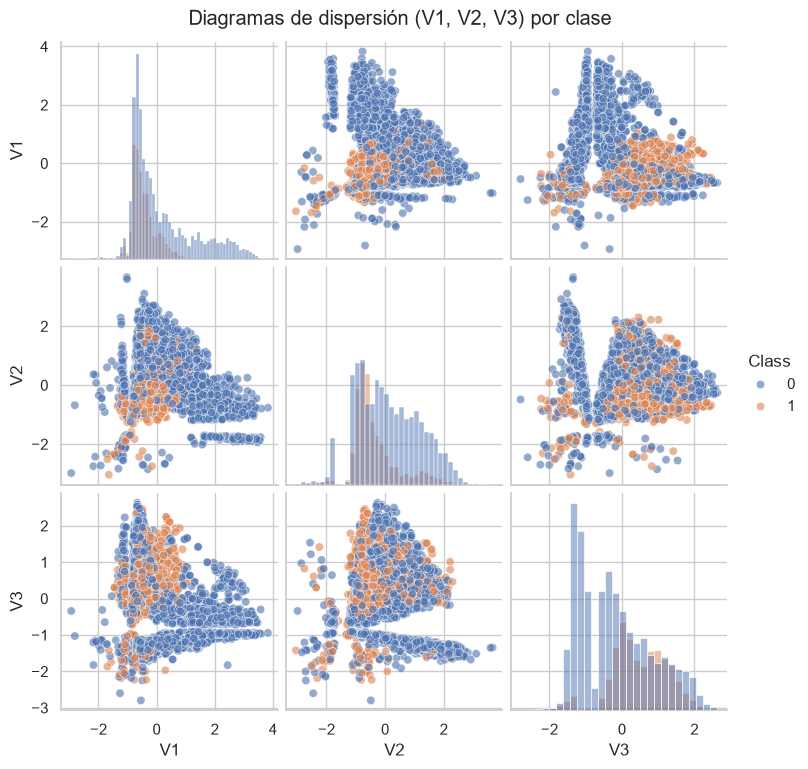

In [9]:
df_viz = X_clf.copy()
df_viz['Class'] = y_clf

# Pairplot limitado (solo primeras 3 variables para claridad)
sns.pairplot(
    df_viz,
    vars=['V1', 'V2', 'V3'],
    hue='Class',
    diag_kind='hist',
    plot_kws={'alpha': 0.6}
)
plt.suptitle('Diagramas de dispersión (V1, V2, V3) por clase', y=1.02)
plt.show()


**2)** Diagramas de barras

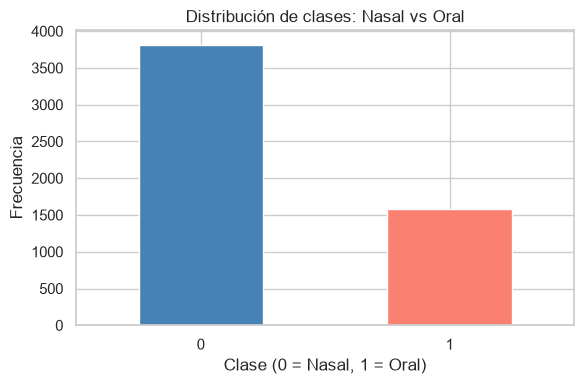

In [10]:
plt.figure(figsize=(6, 4))
y_clf.value_counts().plot(kind='bar', color=['steelblue', 'salmon'])
plt.title('Distribución de clases: Nasal vs Oral')
plt.xlabel('Clase (0 = Nasal, 1 = Oral)')
plt.ylabel('Frecuencia')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


**3)** Diagrama de cajas y bigotes (boxplots)

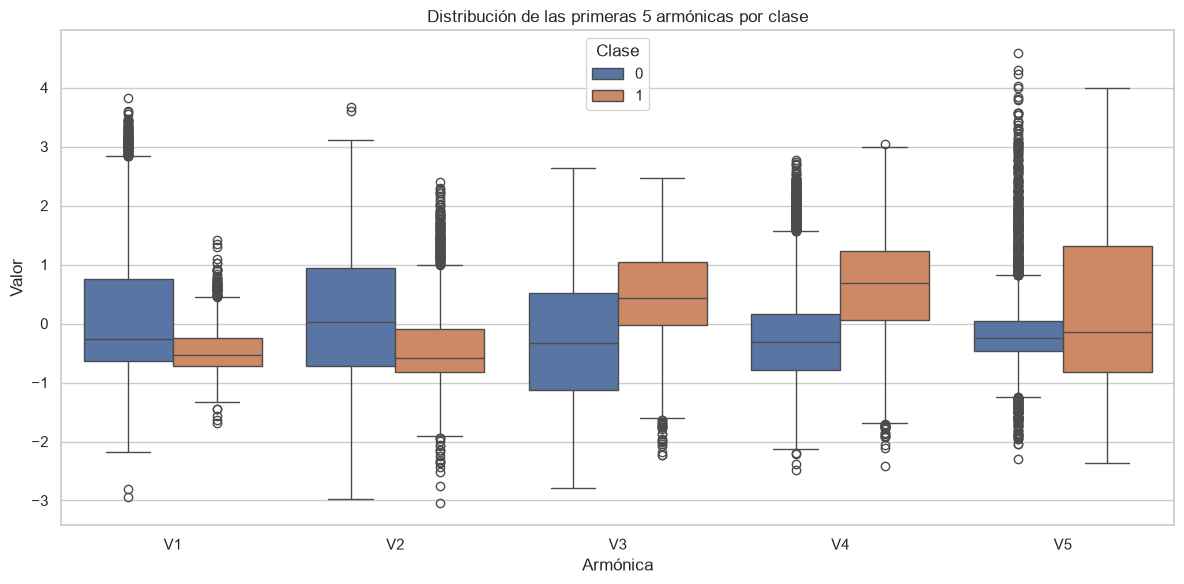

In [11]:
df_viz = X_clf.copy()
df_viz['Class'] = y_clf

# Reorganizar para seaborn
df_melt = df_viz.melt(id_vars='Class', var_name='Armónica', value_name='Valor')

plt.figure(figsize=(12, 6))
sns.boxplot(data=df_melt, x='Armónica', y='Valor', hue='Class')
plt.title('Distribución de las primeras 5 armónicas por clase')
plt.legend(title='Clase')
plt.tight_layout()
plt.show()


**4)** Tabla de contingencia

In [12]:
contingencia = pd.crosstab(df_viz['Class'], columns='count')
print("=== Tabla de contingencia: frecuencia por clase ===")
display(contingencia)

# Proporciones
print("\n=== Proporciones ===")
display(contingencia / contingencia.sum())


=== Tabla de contingencia: frecuencia por clase ===


col_0,count
Class,
0,3818
1,1586



=== Proporciones ===


col_0,count
Class,
0,0.7065
1,0.2935


**5)** Matriz de correlaciones

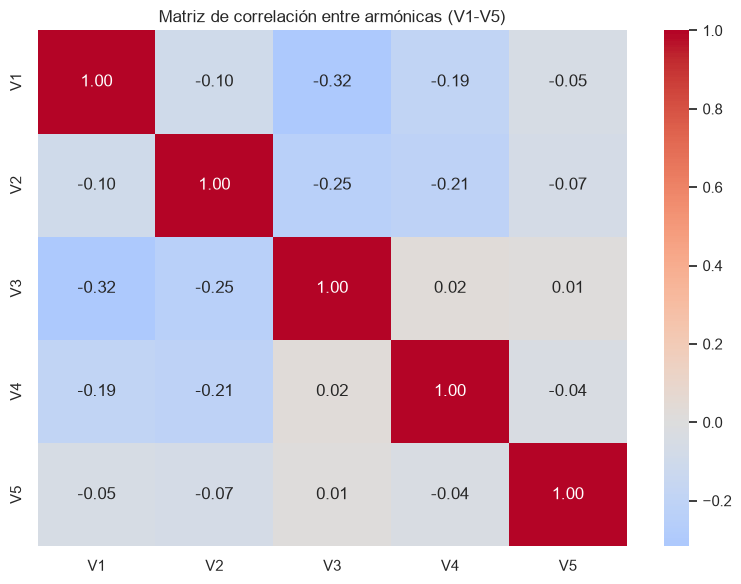

In [13]:

plt.figure(figsize=(8, 6))
corr_matrix = X_clf.corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', center=0, fmt=".2f")
plt.title('Matriz de correlación entre armónicas (V1-V5)')
plt.tight_layout()
plt.show()


### Hallazgos preliminares

De manera general, el dataset se encuentra en buenas condiciones para llevar a cabo los modelos de clasificación. No se cuenta con la presencia de valores nulos, y los tipos de datos de las variables se encuentran en orden. No obstante, para el caso de la variable objetivo (Class), se tuvo que llevar a cabo un proceso de binarización, ya que los resultados se encontraban tipificados como 1 (nasales) y 2 (orales), recodificandose como 0 (nasales) y 1 (orales) para el correcto funcionamiento de los modelos de clasificación. A pesar de que variables como v5 y v4 cuentan con niveles relativamente altos de valores atípicos, estos se conservan debido a las características de los datos en cuestión, en donde las frecuencias atípicas pueden ser relevantes para la distinción entre sonidos nasales y orales.

Por otro lado, el análisis exploratorio nos permite ver el comportamiento general de los datos. La distribución de la variable predictora muestra que los sonidos nasales (O) representan el 71% del total, mientras que los orales solo el 29% , lo que tendrá que tenerse en cuenta en el análisis posterior de las métricas de evaluación. Es este caso, los datos no se balancean, ya que nos interesa predecir tanto nasales como orales, pero si el objetivo del modelo fuera maximizar el desempeño en la predicción para los fonemas orales, esto tendrìa que ser ajustado.

Por otro lado, el heatmap muestra que las variables predictoras son independientes, por lo que no  cuentan con multicolinealidad.

# Ejercicio 4: Modelos de clasificación.

In [14]:
def evaluar_clasificador(modelo, X_train, X_test, y_train, y_test, nombre):
    modelo.fit(X_train, y_train)
    y_pred = modelo.predict(X_test)
    
    # Para ROC-AUC, necesitamos probabilidades (o scores si no hay)
    if hasattr(modelo, "predict_proba"):
        y_proba = modelo.predict_proba(X_test)[:, 1]
    else:
        y_proba = modelo.decision_function(X_test)  # para Perceptrón si no tiene predict_proba

    return {
        'Modelo': nombre,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall': recall_score(y_test, y_pred, zero_division=0),
        'F1': f1_score(y_test, y_pred, zero_division=0)
    }


**DIVISIÓN DE LOS DATOS**

In [15]:
X_train_clf, X_test_clf, y_train_clf, y_test_clf = train_test_split(
    X_clf, y_clf, test_size=0.3, stratify=y_clf, random_state=42
)


### 1) Regresión logística

In [16]:
modelo_lr = Pipeline([
    ('scaler', StandardScaler()),
    ('logreg', LogisticRegression(random_state=42, max_iter=1000))
])

resultados_lr = evaluar_clasificador(
    modelo_lr, X_train_clf, X_test_clf, y_train_clf, y_test_clf, "Regresión Logística"
)


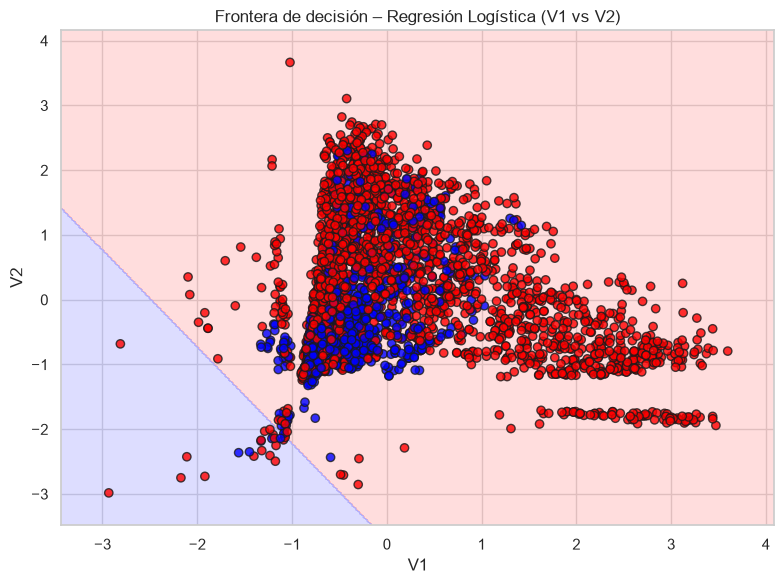

In [17]:
# Frontera de decisión – Regresión Logística (V1 vs V2, V3-V5 en media)
from matplotlib.colors import ListedColormap

# Usar las 5 features: malla en V1 vs V2, V3-V5 fijadas en su media
X_base = X_train_clf.copy()
media_v3 = X_base['V3'].mean()
media_v4 = X_base['V4'].mean()
media_v5 = X_base['V5'].mean()

h = .02
x_min, x_max = X_base['V1'].min() - .5, X_base['V1'].max() + .5
y_min, y_max = X_base['V2'].min() - .5, X_base['V2'].max() + .5
xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))

# Construir grid con las 5 columnas (V3, V4, V5 = media)
n_puntos = xx.ravel().shape[0]
X_grid = np.column_stack([
    xx.ravel(),
    yy.ravel(),
    np.full(n_puntos, media_v3),
    np.full(n_puntos, media_v4),
    np.full(n_puntos, media_v5),
])
X_grid_df = pd.DataFrame(X_grid, columns=X_clf.columns)

Z = modelo_lr.predict(X_grid_df)
Z = Z.reshape(xx.shape)

plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, Z, alpha=0.4, cmap=ListedColormap(['#FFAAAA', '#AAAAFF']))
plt.scatter(X_train_clf['V1'], X_train_clf['V2'], c=y_train_clf, alpha=0.8,
            cmap=ListedColormap(['#FF0000', '#0000FF']), edgecolor='k')
plt.xlabel('V1')
plt.ylabel('V2')
plt.title('Frontera de decisión – Regresión Logística (V1 vs V2)')
plt.tight_layout()
plt.show()


### 2) Árbol de decisión

In [18]:
modelo_dt = DecisionTreeClassifier(
    max_depth=10,          # evita sobreajuste
    min_samples_split=20,
    min_samples_leaf=10,
    random_state=42
)

resultados_dt = evaluar_clasificador(
    modelo_dt, X_train_clf, X_test_clf, y_train_clf, y_test_clf, "Árbol de Decisión"
)


C:\Users\qluis\AppData\Local\Temp\ipykernel_15592\3274941812.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importances, y=feat_names, palette='viridis')


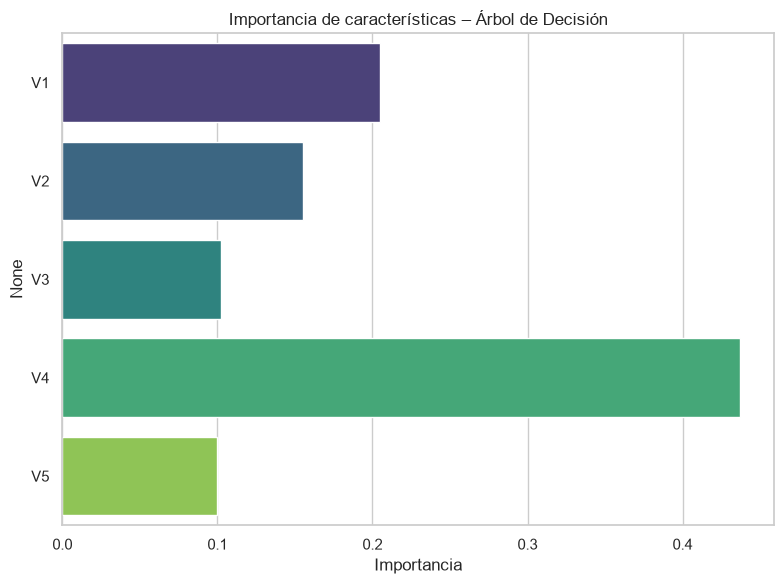

In [19]:
# Importancia de características – Árbol de Decisión
importances = modelo_dt.feature_importances_
feat_names = X_clf.columns
plt.figure(figsize=(8, 6))
sns.barplot(x=importances, y=feat_names, palette='viridis')
plt.xlabel('Importancia')
plt.title('Importancia de características – Árbol de Decisión')
plt.tight_layout()
plt.show()


### 3) KNN

In [20]:
modelo_knn = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', KNeighborsClassifier(n_neighbors=5))
])

resultados_knn = evaluar_clasificador(
    modelo_knn, X_train_clf, X_test_clf, y_train_clf, y_test_clf, "KNN"
)


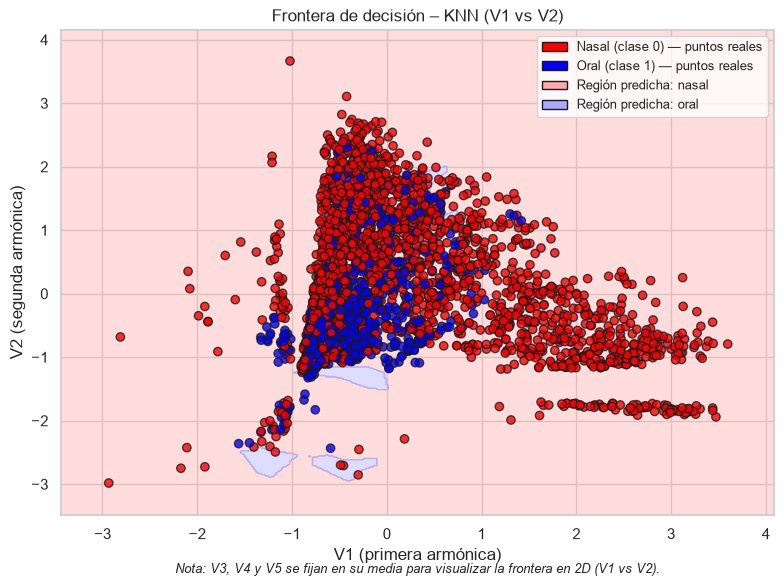

In [21]:
# Frontera de decisión – KNN (V1 vs V2, V3-V5 en media)
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

# Usar las 5 features: malla en V1 vs V2, V3-V5 fijadas en su media
X_base = X_train_clf.copy()
media_v3 = X_base['V3'].mean()
media_v4 = X_base['V4'].mean()
media_v5 = X_base['V5'].mean()

h = .02
x_min, x_max = X_base['V1'].min() - .5, X_base['V1'].max() + .5
y_min, y_max = X_base['V2'].min() - .5, X_base['V2'].max() + .5
xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))

# Construir grid con las 5 columnas (V3, V4, V5 = media)
n_puntos = xx.ravel().shape[0]
X_grid = np.column_stack([
    xx.ravel(),
    yy.ravel(),
    np.full(n_puntos, media_v3),
    np.full(n_puntos, media_v4),
    np.full(n_puntos, media_v5),
])
X_grid_df = pd.DataFrame(X_grid, columns=X_clf.columns)

Z = modelo_knn.predict(X_grid_df)
Z = Z.reshape(xx.shape)

fig, ax = plt.subplots(figsize=(8, 6))
ax.contourf(xx, yy, Z, alpha=0.4, cmap=ListedColormap(['#FFAAAA', '#AAAAFF']))
scatter = ax.scatter(X_train_clf['V1'], X_train_clf['V2'], c=y_train_clf, alpha=0.8,
                     cmap=ListedColormap(['#FF0000', '#0000FF']), edgecolor='k')
ax.set_xlabel('V1 (primera armónica)')
ax.set_ylabel('V2 (segunda armónica)')
ax.set_title('Frontera de decisión – KNN (V1 vs V2)')

# Leyenda explícita: color = clase (nasal / oral)
legend_handles = [
    Patch(facecolor='#FF0000', edgecolor='k', label='Nasal (clase 0) — puntos reales'),
    Patch(facecolor='#0000FF', edgecolor='k', label='Oral (clase 1) — puntos reales'),
    Patch(facecolor='#FFAAAA', edgecolor='k', label='Región predicha: nasal'),
    Patch(facecolor='#AAAAFF', edgecolor='k', label='Región predicha: oral'),
]
ax.legend(handles=legend_handles, loc='best', fontsize=9)

ax.text(0.5, -0.12,
        'Nota: V3, V4 y V5 se fijan en su media para visualizar la frontera en 2D (V1 vs V2).',
        transform=ax.transAxes, ha='center', fontsize=9, style='italic')

plt.tight_layout()
plt.show()


### 4) Perceptrón.

In [22]:
modelo_perceptron = Pipeline([
    ('scaler', StandardScaler()),
    ('perceptron', Perceptron(random_state=42, max_iter=1000, tol=1e-3))
])

resultados_perceptron = evaluar_clasificador(
    modelo_perceptron, X_train_clf, X_test_clf, y_train_clf, y_test_clf, "Perceptrón")


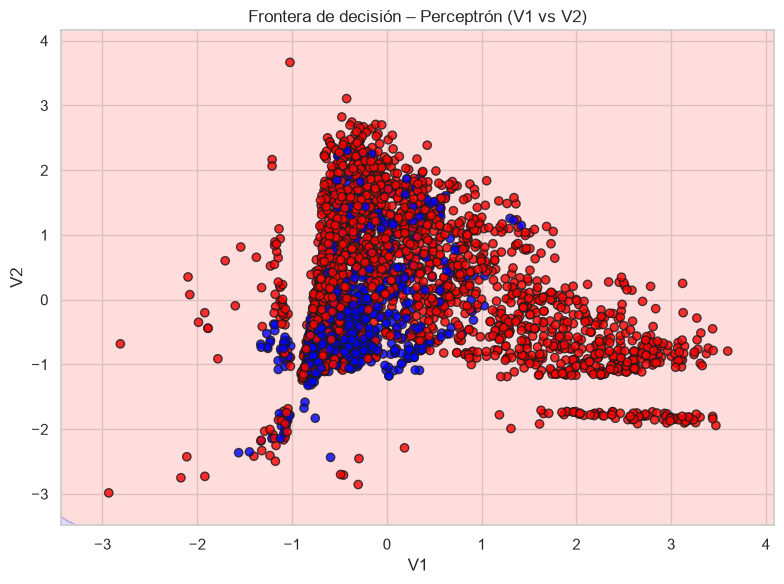

In [23]:
# Frontera de decisión – Perceptrón (V1 vs V2, V3-V5 en media)
from matplotlib.colors import ListedColormap

# Usar las 5 features: malla en V1 vs V2, V3-V5 fijadas en su media
X_base = X_train_clf.copy()
media_v3 = X_base['V3'].mean()
media_v4 = X_base['V4'].mean()
media_v5 = X_base['V5'].mean()

h = .02
x_min, x_max = X_base['V1'].min() - .5, X_base['V1'].max() + .5
y_min, y_max = X_base['V2'].min() - .5, X_base['V2'].max() + .5
xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))

# Construir grid con las 5 columnas (V3, V4, V5 = media)
n_puntos = xx.ravel().shape[0]
X_grid = np.column_stack([
    xx.ravel(),
    yy.ravel(),
    np.full(n_puntos, media_v3),
    np.full(n_puntos, media_v4),
    np.full(n_puntos, media_v5),
])
X_grid_df = pd.DataFrame(X_grid, columns=X_clf.columns)

Z = modelo_perceptron.predict(X_grid_df)
Z = Z.reshape(xx.shape)

plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, Z, alpha=0.4, cmap=ListedColormap(['#FFAAAA', '#AAAAFF']))
plt.scatter(X_train_clf['V1'], X_train_clf['V2'], c=y_train_clf, alpha=0.8,
            cmap=ListedColormap(['#FF0000', '#0000FF']), edgecolor='k')
plt.xlabel('V1')
plt.ylabel('V2')
plt.title('Frontera de decisión – Perceptrón (V1 vs V2)')
plt.tight_layout()
plt.show()


### Evaluación comparada de modelos

,Accuracy,Precision,Recall,F1
Modelo,,,,
Regresión Logística,0.7337,0.5615,0.4223,0.4820
Árbol de Decisión,0.8422,0.7254,0.7437,0.7344
KNN,0.8619,0.7877,0.7248,0.7549
Perceptrón,0.6794,0.4231,0.2542,0.3176


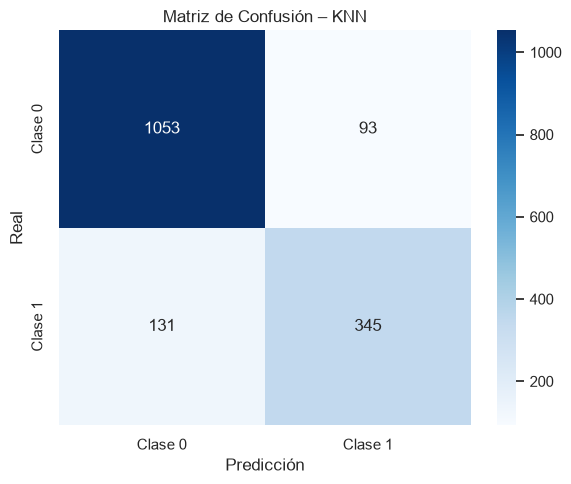

In [24]:
todos_resultados_clf = [
    resultados_lr,
    resultados_dt,
    resultados_knn,
    resultados_perceptron
]

# Crear y mostrar tabla
df_comparacion_clf = pd.DataFrame(todos_resultados_clf).round(4)
df_comparacion_clf = df_comparacion_clf.set_index('Modelo')


display(df_comparacion_clf)

y_pred_knn = modelo_knn.predict(X_test_clf)
cm_knn = confusion_matrix(y_test_clf, y_pred_knn)

# Visualizar con seaborn
plt.figure(figsize=(6, 5))
sns.heatmap(cm_knn, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Clase 0', 'Clase 1'],
            yticklabels=['Clase 0', 'Clase 1'])
plt.title('Matriz de Confusión – KNN')
plt.xlabel('Predicción')
plt.ylabel('Real')
plt.tight_layout()
plt.show()


In [25]:
print("\n Mejor modelo por métrica:")
print(f"• Mayor Accuracy : {df_comparacion_clf['Accuracy'].idxmax()}")
print(f"• Mayor Precision: {df_comparacion_clf['Precision'].idxmax()}")
print(f"• Mayor Recall   : {df_comparacion_clf['Recall'].idxmax()}")
print(f"• Mayor F1       : {df_comparacion_clf['F1'].idxmax()}")



 Mejor modelo por métrica:
• Mayor Accuracy : KNN
• Mayor Precision: KNN
• Mayor Recall   : Árbol de Decisión
• Mayor F1       : KNN


Basado en los resultados anteriores, podemos evaluar el desempeño de los modelos de clasificación, en donde el modelo KNN muestra el mejor desempeño en tres de las cuatro métricas. Se destaca su resultado en *F1 Score*, ya que, si se tiene en cuenta la desproporción entre los sonidos nasales y orales, este presenta la mejor opción para medir el desempeño del modelo, ya que este equilibra precisión con exhaustividad (recall), calculándose como dos veces el producto de la precisión y la exhaustividad, dividido por la suma de la precisión y la exhaustividad, siendo ideal para trabajar con conjuntos de datos desequilibrados (Vina, 2025). 

En base a lo anterior, se escoge al KNN como el mejor modelo para este caso. Su matriz de confusión muestra la proporción de falsos negativos (93) es menor a la de los falsos positivos (131), mostrando un poco más de dificultad para la predicción de fonemas orales reales; sin embargo, la detección de fonemas orales reales sigue siendo alta (72.5%).

# Ejercicio 5: Feedback.

In [26]:
# NOTA: coloca tu captura en assets/fase2-evidencia.png (ruta relativa portable).
from pathlib import Path
from IPython.display import Image, display
ruta_imagen = "assets/fase2-evidencia.png"  # ANTES: ruta absoluta OneDrive (no portable)
p_img = Path(ruta_imagen)
# Buscar tambien desde la raiz del repo (notebook vive en notebooks/04-proyecto-unad/)
for cand in [p_img, Path("../../assets/fase2-evidencia.png"), Path.cwd() / ruta_imagen]:
    if cand.exists():
        p_img = cand
        break
if p_img.exists():
    display(Image(filename=str(p_img), width=800))
else:
    print(f"[info] Imagen no encontrada en {ruta_imagen}: coloca tu captura ahi o ignora esta celda.")


[info] Imagen no encontrada en assets/fase2-evidencia.png: coloca tu captura ahi o ignora esta celda.


# Referencias

Accio (s.f). Qué es el r2 en una linea de tendencia. En *Accio.* https://www.accio.com/business/es/que-es-el-r2-en-una-linea-de-tendencia

Gomes Mantovani, R. (2015). Phoneme. *En OpenML.* https://www.openml.org/search?type=data&status=active&id=1489

Kavlakoglu, E., Murel, J. (s.f). ¿Qué es la multicolinealidad?. En *IBM*. https://www.ibm.com/es-es/think/topics/multicollinearity

Rijn, J. (2014). Cloud. En *OpenML*. https://www.openml.org/search?type=data&status=active&id=210

Vina, A. (2025). Exactitud, precisión y exhaustividad en el aprendizaje automático. En *Ultralytics*. https://www.ultralytics.com/es/blog/accuracy-precision-recall
